# 01 · Data: download, cache, structural checks

Downloads the three parquet shards (about 1.15 GB) to Drive once, caches each row as arrays, then re-runs the
structural checks from the October pipeline. Every number that later notebooks rely on (retained samples,
primary channels, flagged samples) is written to `derived/step0.json`.

Runtime: CPU, High-RAM is not needed. First run about 10 minutes (mostly the download); reruns skip what is cached.

In [1]:
# Bootstrap: same cell in every notebook. On Colab: mount Drive, get the repo, install extras.
# The repo is private: add a read-only GitHub token to Colab Secrets as GH_TOKEN.
import os, sys, subprocess, base64
REPO_URL = "https://github.com/sanjanasinghx/dream2image-es606.git"
if "google.colab" in sys.modules and not os.environ.get("D2I_HEADLESS"):  # headless = run by d2i.runner
    from google.colab import drive, userdata
    drive.mount("/content/drive")
    REPO = "<repo>"
    try:
        auth = base64.b64encode(f"x-access-token:{userdata.get('GH_TOKEN')}".encode()).decode()
        git = ["git", "-c", f"http.extraHeader=Authorization: Basic {auth}"]  # token never written to disk
    except Exception:
        git = ["git"]  # no secret: works once the repo is public
    if not os.path.exists(REPO):
        subprocess.run([*git, "clone", "-q", REPO_URL, REPO], check=True)
    else:
        subprocess.run([*git, "-C", REPO, "pull", "-q"], check=True)
    freeze = lambda: subprocess.run([sys.executable, "-m", "pip", "freeze"], capture_output=True, text=True).stdout
    before = freeze()
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", f"{REPO}/requirements-colab.txt"], check=True)
    if freeze() != before:  # e.g. numpy upgraded under an already-loaded copy -> broken imports
        print("Packages changed: restarting the runtime. When it reconnects, Run all again.")
        os.kill(os.getpid(), 9)
else:
    REPO = os.path.abspath("..")
sys.path.insert(0, REPO)
from d2i import env
cfg = env.load_config()
rng = env.seed_everything(cfg["seed"])
print("data root:", env.data_root())

data root: <data root>


In [2]:
import json
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from d2i import data, checks
tables = env.path(cfg, "results") / "tables"; tables.mkdir(exist_ok=True)
figs = env.path(cfg, "results") / "figures"; figs.mkdir(exist_ok=True)
load = lambda sid, col=None: data.load_eeg(cfg, sid, col)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


## 1. Download and cache (resumable)

In [3]:
shards = data.download(cfg)
print([s.name for s in shards])
n = data.cache_rows(cfg, shards)
metas = data.load_meta(cfg)
assert len(metas) == cfg["dataset"]["expected_n_rows"], f"{len(metas)} rows cached"

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

['train-00000-of-00003.parquet', 'train-00001-of-00003.parquet', 'train-00002-of-00003.parquet']


cached 129 rows in 38s


## 2. Is every EEG column z-scored on its own?
If yes, absolute power is gone: only spectral *shape* can be compared across samples.

In [4]:
scaling = checks.scaling_table(cfg, metas, load)
scaling.to_csv(tables / "scaling_check.csv", index=False)
live = scaling[scaling.sd > cfg["dataset"]["dead_sd_floor"]]
print(live.groupby("source")[["is_z"]].mean().rename(columns={"is_z": "frac_live_channels_z_scored"}))

          frac_live_channels_z_scored
source                               
eeg_120s                     1.000000
eeg_15s                      0.185382
eeg_30s                      0.245886
eeg_60s                      0.585189


## 3. Are the 15/30/60 s windows the tail of the 120 s recording?

In [5]:
nest = checks.nesting_table(metas)
nest.to_csv(tables / "nesting_check.csv", index=False)
counts = nest.groupby(["window_s", "verdict"]).size().unstack(fill_value=0)
print(counts)
mis_frac = (nest.verdict == "misaligned").mean()
assert mis_frac <= cfg["checks"]["misaligned_stop_fraction"], f"{mis_frac:.1%} misaligned: stop and inspect"

verdict   identical  length-mismatch  misaligned
window_s                                        
15              118                6           5
30              118                6           5
60              118                6           5


## 4. Participants, sites and exclusions

In [6]:
parts = checks.participants_table(metas, data.parse_title)
parts.to_csv(tables / "participants.csv", index=False)
excl = checks.exclusions_table(cfg, metas, nest, parts)
excl.to_csv(tables / "sample_exclusions.csv", index=False)
ret = excl[excl.retained]
print(f"participants: {parts.participant.nunique()} (paper: {cfg['participant']['expected_n']})")
print(f"retained {len(ret)}/{len(excl)} samples from {ret.participant.nunique()} participants")
print(ret.groupby("site").agg(samples=("sample_id", "size"), participants=("participant", "nunique")))
print("awakening tags (subject site):", ret.tag_class.fillna("none").value_counts().to_dict())
print("excluded:\n", excl.loc[~excl.retained, ["sample_id", "title", "reasons"]].to_string(index=False))
assert parts.participant.nunique() == cfg["participant"]["expected_n"]

participants: 38 (paper: 38)
retained 122/129 samples from 37 participants
         samples  participants
site                          
case          22            14
subject      100            23
awakening tags (subject site): {'SO': 70, 'none': 22, 'Morning': 12, 'REM': 10, 'NREM': 8}
excluded:
 sample_id                 title            reasons
     s022         case32_sub122       n_channels=6
     s023         case33_sub122       n_channels=6
     s026    subject010_REM.edf nesting_misaligned
     s054 subject126_SO10.edfOK nesting_misaligned
     s072 subject249_SO10.edfOK nesting_misaligned
     s089   subject347_SO10.edf nesting_misaligned
     s115    subject422_REM.edf nesting_misaligned


## 5. Primary channel set
Channels live in at least 95% of retained samples (Cz is dead in every `subject`-site recording).

In [7]:
avail = checks.channel_availability(cfg, scaling, excl)
avail.to_csv(tables / "channel_availability.csv", index=False)
primary = avail.loc[avail.primary, "channel"].tolist()
print(avail.to_string(index=False))
print("primary:", primary)

channel  n_live   n  frac_live  primary
     C3     122 122   1.000000     True
     C4     122 122   1.000000     True
     Cz      22 122   0.180328    False
     F3     122 122   1.000000     True
     F4     122 122   1.000000     True
     F7     122 122   1.000000     True
     F8     122 122   1.000000     True
    Fp1     122 122   1.000000     True
    Fp2     122 122   1.000000     True
    Fpz     122 122   1.000000     True
     Fz     122 122   1.000000     True
     O1     122 122   1.000000     True
     O2     122 122   1.000000     True
     Oz     122 122   1.000000     True
     P3     122 122   1.000000     True
     P4     122 122   1.000000     True
     Pz     122 122   1.000000     True
primary: ['C3', 'C4', 'F3', 'F4', 'F7', 'F8', 'Fp1', 'Fp2', 'Fpz', 'Fz', 'O1', 'O2', 'Oz', 'P3', 'P4', 'Pz']


## 6. Is the undocumented channel order spatially plausible?

In [8]:
order_res, corr = checks.channel_order_check(cfg, metas, load, rng)
corr.to_csv(tables / "channel_corr_mean.csv")
print(order_res)

<repo>/d2i/checks.py:130: FutureWarning: Montage name 'standard_1020' is deprecated and will be removed in MNE 1.14. Use 'colin27_1020' instead.
  pos = mne.channels.make_standard_montage("standard_1020").get_positions()["ch_pos"]


{'spearman_corr_vs_neg_distance': 0.8701016172892514, 'perm_p': 0.0001999600079984003, 'null_p95': 0.16810075855159592, 'n_samples_used': 127}


## 7. Site differences in the spectrum
If the sites separate completely above 45 Hz, anything above ~30 Hz is a site marker, not brain signal.

         count       min    median       max
site                                        
case        24 -3.228741 -2.035580 -1.040638
subject    105 -7.347320 -5.711694 -3.911839


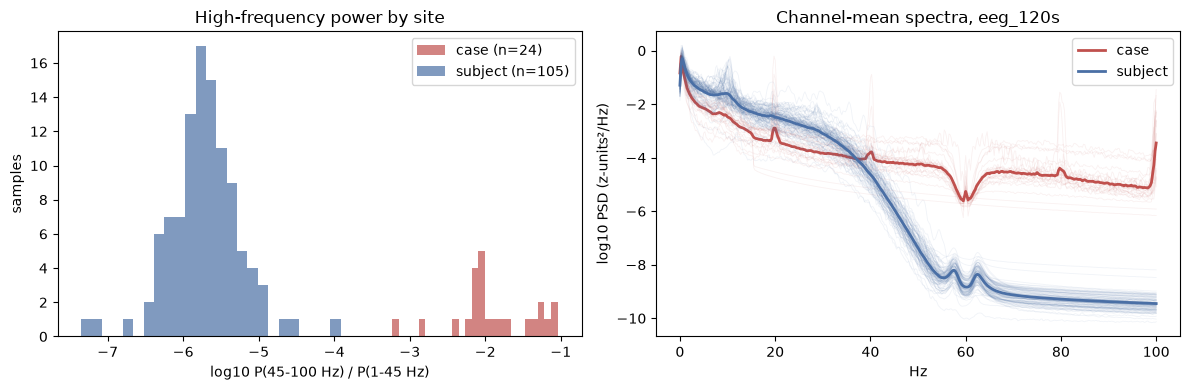

In [9]:
hf, f, spectra = checks.site_spectra(cfg, metas, parts, load)
hf.to_csv(tables / "site_hf_fraction.csv", index=False)
by = hf.groupby("site")["log10_frac_45_100"].agg(["count", "min", "median", "max"])
print(by)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
colors = {"case": "#c0504d", "subject": "#4a6fa5"}
m = f <= 100
for s, c in colors.items():
    sel = (hf.site == s).values
    ax[0].hist(hf.log10_frac_45_100[sel], bins=25, alpha=.7, color=c, label=f"{s} (n={sel.sum()})")
    ax[1].plot(f[m], spectra[sel][:, m].T, color=c, alpha=.08, lw=.6)
    ax[1].plot(f[m], spectra[sel][:, m].mean(0), color=c, lw=2, label=s)
ax[0].set(xlabel="log10 P(45-100 Hz) / P(1-45 Hz)", ylabel="samples", title="High-frequency power by site")
ax[1].set(xlabel="Hz", ylabel="log10 PSD (z-units²/Hz)", title="Channel-mean spectra, eeg_120s")
for a in ax: a.legend()
fig.tight_layout(); fig.savefig(figs / "site_spectra.pdf"); fig.savefig(figs / "site_spectra.png", dpi=150)

## 8. Per-epoch scale (sensitivity flags)

In [10]:
so = checks.scaling_outliers(cfg, excl, load)
so.to_csv(tables / "scaling_outliers.csv", index=False)
flagged = so.loc[so.retained & so.scaling_flag, "sample_id"].tolist()
print("flagged for sensitivity analysis:", flagged)
print("samples with full 120 s (E1 available):", int((so.retained & (so.len_s >= 120)).sum()))

flagged for sensitivity analysis: ['s013', 's040', 's042', 's105']
samples with full 120 s (E1 available): 22


## 9. Save the decisions later notebooks use

In [11]:
step0 = {
    "n_rows": len(metas),
    "retained": ret.sample_id.tolist(),
    "n_participants_retained": int(ret.participant.nunique()),
    "primary_channels": primary,
    "scaling_flagged": flagged,
    "nesting_counts": {str(k): v for k, v in counts.to_dict().items()},
    "channel_order": order_res,
    "site_hf": by.round(3).to_dict(orient="index"),
}
out = env.path(cfg, "derived") / "step0.json"
out.write_text(json.dumps(step0, indent=2, default=str))
env.write_manifest(cfg, "01_data", [out, *sorted(tables.glob("*.csv"))])
print(json.dumps({k: v for k, v in step0.items() if k != "retained"}, indent=1, default=str))

{
 "n_rows": 129,
 "n_participants_retained": 37,
 "primary_channels": [
  "C3",
  "C4",
  "F3",
  "F4",
  "F7",
  "F8",
  "Fp1",
  "Fp2",
  "Fpz",
  "Fz",
  "O1",
  "O2",
  "Oz",
  "P3",
  "P4",
  "Pz"
 ],
 "scaling_flagged": [
  "s013",
  "s040",
  "s042",
  "s105"
 ],
 "nesting_counts": {
  "identical": {
   "15": 118,
   "30": 118,
   "60": 118
  },
  "length-mismatch": {
   "15": 6,
   "30": 6,
   "60": 6
  },
  "misaligned": {
   "15": 5,
   "30": 5,
   "60": 5
  }
 },
 "channel_order": {
  "spearman_corr_vs_neg_distance": 0.8701016172892514,
  "perm_p": 0.0001999600079984003,
  "null_p95": 0.16810075855159592,
  "n_samples_used": 127
 },
 "site_hf": {
  "case": {
   "count": 24,
   "min": -3.229,
   "median": -2.036,
   "max": -1.041
  },
  "subject": {
   "count": 105,
   "min": -7.347,
   "median": -5.712,
   "max": -3.912
  }
 }
}
